# LLM Instruct fine-tuning: train, evaluate, export and publish

English | [简体中文](01_finetune.zh-CN.ipynb)

## Goal
Run an independent assistant-only supervised instruction tuning workflow. Model, hardware and full/LoRA training are configurable. The default is an offline random tiny Llama decoder and synthetic English data; **this verifies functionality, not domain quality**.

## Setup
From the repository root: `python -m pip install -e '.[llm-instruct,notebooks]'`.
On Colab, place the repository at `/content/advai-notebooks`, install its matching extra and set `ROOT` below. CUDA/MPS and real-model quality require separate validation.

In [1]:
from pathlib import Path
import sys
import importlib.metadata

# Colab: ROOT = Path("/content/advai-notebooks")
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise RuntimeError("Set ROOT to the repository directory")
sys.path.insert(0, str(ROOT / "src"))
from huggingface_hub.utils import disable_progress_bars
from transformers.utils.logging import disable_progress_bar
disable_progress_bars()
disable_progress_bar()
for name in ("torch", "transformers", "peft", "accelerate"):
    print(name, importlib.metadata.version(name))

torch 2.14.0
transformers 5.18.0
peft 0.18.1
accelerate 1.15.0


## Steps
### 1. Configure and validate grouped data
Each execution creates a new output directory. Choose `lora.yaml` for adapters or edit `hf.yaml` for a real model and your own data. Group documents/conversations before splitting; validation selects checkpoints and test only reports results.

In [2]:
import tempfile
from advai_notebooks.llm.instruct.config import load_config
from advai_notebooks.llm.instruct.data import load_data, prepare_data
from advai_notebooks.llm.instruct.model import InstructModel
from advai_notebooks.common.runtime import setup

CONFIG = ROOT / "configs/llm/instruct/smoke.yaml"
cfg = load_config(CONFIG, root=ROOT)
parent = ROOT / "outputs/llm/instruct"
parent.mkdir(parents=True, exist_ok=True)
RUN_DIR = Path(tempfile.mkdtemp(prefix="notebook-", dir=parent)) / "run"
cfg.output_dir = str(RUN_DIR)
rows, data_summary = load_data(cfg)
print(data_summary)
print("Model:", cfg.model.id, "Training:", cfg.training.method)
print("Device:", cfg.runtime.device, "Run:", RUN_DIR)

{'rows': 12, 'splits': {'train': 8, 'validation': 2, 'test': 2}, 'groups': 12, 'fingerprint': 'd41f8adb26fb5c10e4f7a0747b5e351c4755d98afc4199cc48fe53aef54bb7d6'}
Model: tiny Training: full
Device: cpu Run: /Users/xuyi/Documents/workspace/advai-notebooks/outputs/llm/instruct/notebook-t9ui40j7/run


### 2. Inspect supervised token positions
Instruct masks system/user/role markers and supervises assistant responses and template-defined end markers. Fast tokenizer offsets prevent trailing whitespace from spilling into later user turns. Overlong conversations are rejected by default.

In [3]:
preview_model = InstructModel(cfg.model, setup(cfg), cfg.root, generation=cfg.generation)
prepared = prepare_data(rows, preview_model, cfg)
print("Encoded rows:", {split: len(values) for split, values in prepared.items()})
example = prepared["train"][0]
print("Input:", preview_model.tokenizer.convert_ids_to_tokens(example["input_ids"]))
print("Supervised:", preview_model.tokenizer.convert_ids_to_tokens(
    [token for token in example["labels"][1:] if token != -100]))
del preview_model

Encoded rows: {'train': 8, 'validation': 2, 'test': 2}
Input: ['<|system|>', 'answer', 'only', '<|end|>', '<|user|>', 'what', 'color', 'is', 'the', 'sky', '?', '<|end|>', '<|assistant|>', 'blue', '<|end|>', '<|user|>', 'what', 'color', 'is', 'the', 'grass', '?', '<|end|>', '<|assistant|>', 'green', '<|end|>']
Supervised: ['blue', '<|end|>', 'green', '<|end|>']


### 3. Run the full training lifecycle
The pipeline records the baseline, trains, evaluates validation each epoch, selects by token-weighted NLL including epoch zero, evaluates test and exports. No data or models are uploaded.

In [4]:
from advai_notebooks.llm.instruct.pipeline import run

report = run(cfg)
print("Completed:", report["training"]["completed"])
print("Selected epoch:", report["training"]["best_epoch"])
print("Baseline test:", report["baseline_test"]["metrics"])
print("Selected test:", report["finetuned_test"]["metrics"])
print("Test supervised tokens:", report["finetuned_test"]["supervised_tokens"])

Completed: True
Selected epoch: 2
Baseline test: {'nll': 4.861311912536621, 'perplexity': 129.1935816569342, 'exact_match': 0.0}
Selected test: {'nll': 4.737435340881348, 'perplexity': 114.14109298393883, 'exact_match': 0.0}
Test supervised tokens: 4


### 4. Inspect validation NLL and selected epoch
Every point is a measured checkpoint on the same validation split. NLL is weighted by supervised token count. This tiny-data curve does not establish domain quality or statistical significance.

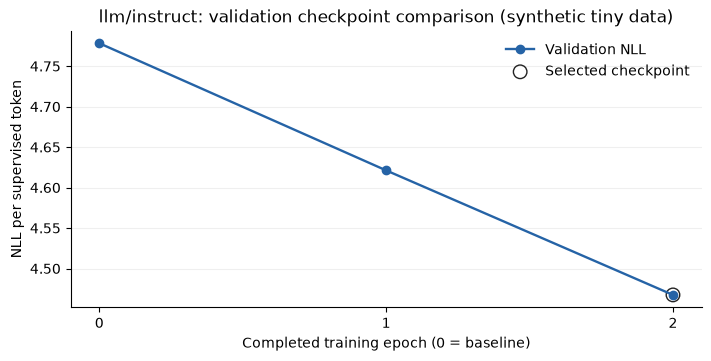

Validation supervised tokens: 6


In [5]:
import json
import matplotlib.pyplot as plt

baseline_validation = json.loads((RUN_DIR / "baseline_validation.json").read_text())
epochs = [0] + [r["epoch"] for r in report["training"]["history"]]
nll = [baseline_validation["metrics"]["nll"]] + [
    r["validation"]["metrics"]["nll"] for r in report["training"]["history"]]
selected_epoch = report["training"]["best_epoch"]
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.plot(epochs, nll, color="#2563a6", marker="o", linewidth=1.7, label="Validation NLL")
ax.scatter([selected_epoch], [nll[epochs.index(selected_epoch)]],
           s=95, facecolors="none", edgecolors="#222222", label="Selected checkpoint")
ax.set(title=f"{cfg.kind}: validation checkpoint comparison (synthetic tiny data)",
       xlabel="Completed training epoch (0 = baseline)", ylabel="NLL per supervised token")
ax.set_xticks(epochs)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.savefig(RUN_DIR / "validation-nll.png", dpi=140)
plt.show()
print("Validation supervised tokens:", baseline_validation["supervised_tokens"])

## Checks
### 5. Reload exported weights and infer
Full exports are native Transformers models. LoRA exports record an exact base revision; tiny/local bases are bundled. Optional merged exports reload a copy, preserving the active adapter model.

In [6]:
model = InstructModel.load(report["export"], device="cpu")
response = model.chat([{"role": "user", "content": "what color is the sky ?"}], max_new_tokens=8)
print("Generated continuation/response:", response)
metadata = json.loads((Path(report["export"]) / "advai_metadata.json").read_text())
print("Export format:", metadata["format"])
if cfg.training.method == "lora":
    merged_path = model.save(RUN_DIR / "merged-export", merged=True)
    merged = InstructModel.load(merged_path)
    assert merged.chat([{"role": "user", "content": "what color is the sky ?"}], max_new_tokens=8) == response
    print("Merged export preserves greedy output:", merged_path)

Generated continuation/response: green green green green green green green green
Export format: full


### 6. Verify completed-run recovery
The `latest` alias resolves `latest.json` to a complete native Trainer checkpoint with optimizer, scheduler and RNG state. An inference export cannot resume. Changing config/data/packages/source requires a new experiment.

In [7]:
recovered = run(cfg, resume=RUN_DIR / "latest")
assert recovered["training"] == report["training"]
assert recovered["finetuned_test"] == report["finetuned_test"]
print("Completed checkpoint recovery preserves the selected test report.")

Completed checkpoint recovery preserves the selected test report.


## Next Steps
### 7. Preview the Hugging Face inference package
The default validates an **offline dry run**. Cards are English; raw records, optimizer/RNG state, credentials and logs are excluded. Publishing requires explicitly setting `UPLOAD_TO_HUB=True` and using a repository you control. No LLM demo repository has been created by this notebook's default run.

Replace synthetic fixtures with grouped domain data and evaluate target tasks. QLoRA, packing, multi-device and preference training are future extensions. See [the guide](../../../docs/llm.md).

In [8]:
from advai_notebooks.llm.instruct.publish import publish
from advai_notebooks.common.artifacts import write_json

UPLOAD_TO_HUB = False
REPO_ID = "widebluesky/wbs-llm-instruct-demo"
publication = publish(report["export"], REPO_ID, dry_run=not UPLOAD_TO_HUB, private=True)
write_json(RUN_DIR / "publication.json", publication)
print({key: publication[key] for key in ("status", "repo_id", "private")})
print("Inference package files:", len(publication["files"]))

{'status': 'dry_run', 'repo_id': 'widebluesky/wbs-llm-instruct-demo', 'private': True}
Inference package files: 8
